In [1]:
# ==============================
# BÀI 1: LINEAR REGRESSION
# ==============================

import numpy as np
from sklearn.linear_model import LinearRegression

# 1. Tạo dữ liệu giả lập
np.random.seed(42)

X = np.random.rand(100, 1) * 10

# Công thức y = 2X + 1 + nhiễu
noise = np.random.randn(100, 1)

y = 2 * X + 1 + noise

# 2. Khởi tạo mô hình
model = LinearRegression()

# 3. Huấn luyện mô hình
model.fit(X, y)

# 4. In kết quả
print("Coefficient:", model.coef_[0][0])

print("Intercept:", model.intercept_[0])

# 5. Dự đoán thử
y_pred = model.predict(X)

print("5 giá trị thực tế:", y[:5].flatten())

print("5 giá trị dự đoán:", y_pred[:5].flatten())

Coefficient: 1.9540226772876965
Intercept: 1.2150961575467498
5 giá trị thực tế: [ 8.57784945 19.71527878 15.73163961 10.98560077  3.90070092]
5 giá trị dự đoán: [ 8.53369502 19.7922693  15.51842378 12.9130187   4.26373577]


In [2]:
# ==============================
# BÀI 2: ĐÁNH GIÁ MÔ HÌNH
# ==============================

import numpy as np

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# 1. Load dữ liệu Diabetes
diabetes = load_diabetes()

# Chỉ lấy 1 đặc trưng BMI
X = diabetes.data[:, [2]]

# Giá trị mục tiêu
y = diabetes.target

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

# 2. Chia dữ liệu Train/Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Số lượng dữ liệu Train:", len(X_train))
print("Số lượng dữ liệu Test:", len(X_test))

# 3. Khởi tạo và huấn luyện mô hình
model = LinearRegression()

model.fit(X_train, y_train)

# 4. Dự đoán trên tập Test
y_pred = model.predict(X_test)

# 5. Đánh giá mô hình

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

# 6. In kết quả
print("\n===== KẾT QUẢ ĐÁNH GIÁ =====")

print("MAE:", mae)

print("MSE:", mse)

print("R-squared:", r2)


# Ý NGHĨA CÁC CHỈ SỐ:
#
# MAE: Sai số tuyệt đối trung bình giữa giá trị thực tế
# và giá trị dự đoán. MAE càng nhỏ càng tốt.
#
# MSE: Trung bình bình phương sai số.
# MSE càng nhỏ thì mô hình dự đoán càng tốt.
#
# R-squared (R2): Đo mức độ mô hình giải thích được
# sự biến thiên của dữ liệu.
# R2 càng gần 1 thì mô hình thường càng tốt.

Kích thước X: (442, 1)
Kích thước y: (442,)
Số lượng dữ liệu Train: 353
Số lượng dữ liệu Test: 89

===== KẾT QUẢ ĐÁNH GIÁ =====
MAE: 52.259976445345536
MSE: 4061.8259284949268
R-squared: 0.23335039815872138


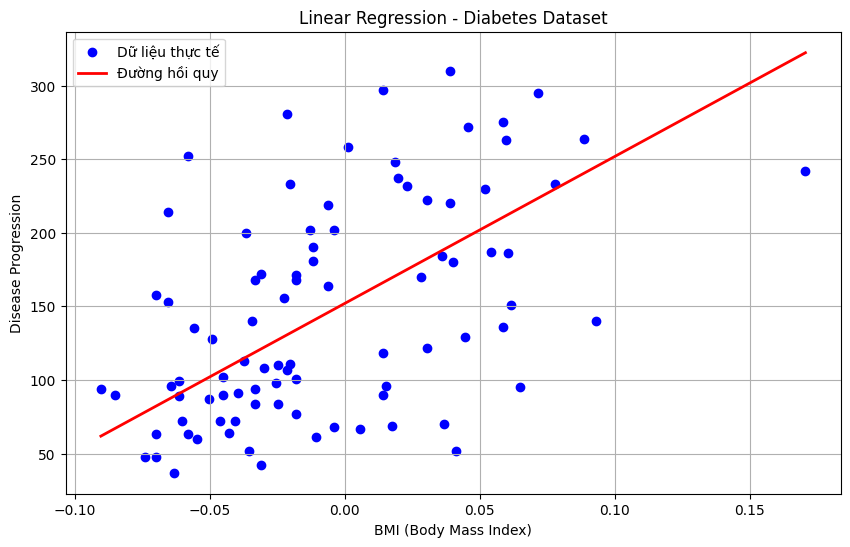

In [3]:
# ==============================
# BÀI 3: TRỰC QUAN HÓA KẾT QUẢ
# ==============================

import matplotlib.pyplot as plt
import numpy as np

# 1. Vẽ biểu đồ Scatter Plot
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test,
    y_test,
    color='blue',
    label='Dữ liệu thực tế'
)

# 2. Sắp xếp X để vẽ đường hồi quy
X_sorted = np.sort(X_test, axis=0)

# 3. Dự đoán theo X đã sắp xếp
y_sorted_pred = model.predict(X_sorted)

# 4. Vẽ đường hồi quy
plt.plot(
    X_sorted,
    y_sorted_pred,
    color='red',
    linewidth=2,
    label='Đường hồi quy'
)

# 5. Đặt tiêu đề và tên trục
plt.title('Linear Regression - Diabetes Dataset')

plt.xlabel('BMI (Body Mass Index)')

plt.ylabel('Disease Progression')

# 6. Hiển thị chú thích
plt.legend()

plt.grid(True)

# 7. Hiển thị biểu đồ
plt.show()

Kích thước dữ liệu X: (20640, 8)
Kích thước dữ liệu y: (20640,)
Train: (16512, 8)
Test: (4128, 8)

===== KẾT QUẢ ĐÁNH GIÁ =====
Mean Squared Error (MSE): 0.5558915986952443


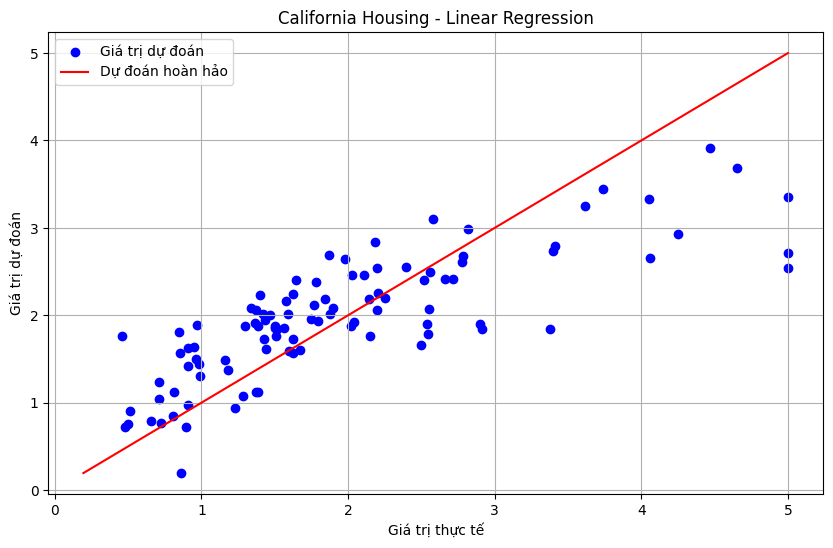

In [4]:
# ==============================
# BÀI 4: QUY TRÌNH MACHINE LEARNING
# ==============================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error


# ==============================
# BƯỚC 1: LOAD DATA
# ==============================

# Tải dữ liệu California Housing
housing = fetch_california_housing()

X = housing.data

y = housing.target

print("Kích thước dữ liệu X:", X.shape)

print("Kích thước dữ liệu y:", y.shape)


# ==============================
# BƯỚC 2: CHIA TRAIN / TEST
# ==============================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)

print("Test:", X_test.shape)


# ==============================
# BƯỚC 3: PREPROCESSING (SCALING)
# ==============================

scaler = StandardScaler()

# Học cách chuẩn hóa từ tập Train
X_train_scaled = scaler.fit_transform(X_train)

# Áp dụng cách chuẩn hóa đó cho tập Test
X_test_scaled = scaler.transform(X_test)


# ==============================
# BƯỚC 4: TRAIN MODEL
# ==============================

model = LinearRegression()

# Huấn luyện mô hình
model.fit(X_train_scaled, y_train)

# Dự đoán trên tập Test
y_pred = model.predict(X_test_scaled)


# ==============================
# BƯỚC 5: EVALUATE (MSE)
# ==============================

mse = mean_squared_error(y_test, y_pred)

print("\n===== KẾT QUẢ ĐÁNH GIÁ =====")

print("Mean Squared Error (MSE):", mse)


# ==============================
# BƯỚC 6: VISUALIZE
# ==============================

plt.figure(figsize=(10, 6))

# Lấy 100 giá trị đầu tiên để trực quan hóa
plt.scatter(
    y_test[:100],
    y_pred[:100],
    color='blue',
    label='Giá trị dự đoán'
)

# Đường dự đoán hoàn hảo
min_value = min(y_test[:100].min(), y_pred[:100].min())

max_value = max(y_test[:100].max(), y_pred[:100].max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color='red',
    label='Dự đoán hoàn hảo'
)

plt.xlabel('Giá trị thực tế')

plt.ylabel('Giá trị dự đoán')

plt.title('California Housing - Linear Regression')

plt.legend()

plt.grid(True)

plt.show()